<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/gg_lockup.png" alt="Global Gateway · European Union" height="64"/>

**Financiado pela União Europeia** · Programa de Parceria Espacial África–UE · Reforço dos Alertas Precoces em África (SEWA)

# AIFS e IFS lado a lado sobre o Senegal 🤖
### Dados abertos e gratuitos do ECMWF · aprendizagem automática e física · sem conta

> ⚠️ **Tradução:** este notebook foi traduzido do inglês com a ajuda de IA e revisto na medida do possível. Em caso de dúvida, prevalece a [versão inglesa](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/aifs_vs_ifs.ipynb). Comunique quaisquer erros no [GitHub](https://github.com/piddy376/visits-weather-notebooks/issues).

🌐 [English](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/aifs_vs_ifs.ipynb) · [Français](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/aifs_vs_ifs_fr.ipynb) · [Português](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/aifs_vs_ifs_pt.ipynb)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/aifs_vs_ifs_pt.ipynb)

O ECMWF produz duas previsões globais, ambas em **dados abertos**: o **IFS**, baseado na física, e o **AIFS**, o
modelo de aprendizagem automática, que calcula uma previsão a dez dias em minutos. Este notebook usa a mesma execução
de ambos, cartografa lado a lado a temperatura a 2 m a cerca de dois dias e meio e, depois, a diferença entre os dois.

**O que precisa:** uma conta Google (para usar o Colab). Nenhuma outra conta, sem custos, nada para instalar. Tudo corre nos computadores da Google: os dados são descarregados lá, não no seu telemóvel
ou computador, por isso uma ligação lenta ou móvel é suficiente.

| Dados | O que este notebook usa | Licença |
|---|---|---|
| Previsão IFS do ECMWF, 0,25° | Temperatura a 2 m, última execução | CC BY 4.0, dados abertos |
| Previsão AIFS Single do ECMWF, 0,25° | Temperatura a 2 m, a mesma execução | CC BY 4.0, dados abertos |

**Ferramentas:** [earthkit](https://earthkit.ecmwf.int), as ferramentas Python gratuitas e de código aberto do ECMWF para dados meteorológicos e climáticos.

*Clique em **Ambiente de execução → Executar tudo** (Runtime → Run all). A primeira execução demora alguns minutos, sobretudo para instalar as ferramentas.*

Implementado por:&nbsp;&nbsp;<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/ECMWF_Core_Logo_RGB.png" alt="ECMWF" height="30"/>

In [ ]:
# Instalar as ferramentas de código aberto (Colab / máquina nova). Alguns minutos da primeira vez.
%pip install -q "earthkit-data[ecmwf-opendata]" earthkit-plots

In [2]:
import pyproj                     # importar antes de earthkit.data (evita um erro ao fechar)
import datetime as dt
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import numpy as np

DIAS = ["segunda-feira", "terça-feira", "quarta-feira", "quinta-feira", "sexta-feira", "sábado", "domingo"]
MESES = ["janeiro", "fevereiro", "março", "abril", "maio", "junho", "julho", "agosto", "setembro", "outubro",
         "novembro", "dezembro"]
def dia(d): return f"{DIAS[d.weekday()]}, {d.day} de {MESES[d.month - 1]}"     # datas em português
def data_pt(d): return f"{d.day} de {MESES[d.month - 1]} de {d.year}"

## 1 · Escolher a área e o prazo de previsão

In [3]:
AREA = [22.0, -22.0, 8.0, -6.0]             # norte, oeste, sul, este
STEP = 60                                   # horas após o início da execução (cerca de dois dias e meio)
CITIES = [("Dakar", 14.716, -17.467), ("Saint-Louis", 16.018, -16.489), ("Touba", 14.850, -15.883),
          ("Tambacounda", 13.771, -13.667), ("Ziguinchor", 12.583, -16.272), ("Kédougou", 12.557, -12.174)]

def label_cities(ax):
    for name, la, lo in CITIES:
        ax.scatter([lo], [la], s=36, color="#ffd23f", edgecolors="#1a1a1a", linewidths=0.8, zorder=10,
                   transform=ccrs.PlateCarree())
        ax.text(lo, la, f"  {name}", transform=ccrs.PlateCarree(), fontsize=10, fontweight="bold", zorder=11,
                color="#1d2230", path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])

## 2 · Descarregar as duas previsões (dados abertos do ECMWF, 0,25°)

In [4]:
def get(model):
    for source in ("ecmwf", "aws", "google"):  # primeiro o ECMWF, depois os espelhos na nuvem se estiver ocupado
        try:
            fl = ekd.from_source("ecmwf-open-data", source=source, model=model, param="2t", step=STEP).to_fieldlist()
            break
        except Exception as err:
            print(f"{source} não responde ({type(err).__name__}), a tentar o espelho seguinte")
    x = fl.to_xarray()
    x = x.assign_coords(longitude=((x.longitude + 180) % 360) - 180).sortby("longitude")
    x = x.sel(latitude=slice(AREA[0], AREA[2]), longitude=slice(AREA[1], AREA[3]))
    return fl, x[list(x.data_vars)[0]].squeeze() - 273.15

ifs_fl, ifs = get("ifs")
aifs_fl, aifs = get("aifs-single")
run, valid = ifs_fl[0].time.base_datetime(), ifs_fl[0].time.valid_datetime()
assert aifs_fl[0].time.base_datetime() == run, "os dois modelos vêm de execuções diferentes: execute a célula outra vez"
diff = aifs - ifs
print(f"Execução de {data_pt(run)} às {run:%H} UTC, válida para {dia(valid)} às {valid:%H}:00 UTC")
print(f"IFS de {float(ifs.min()):.0f} a {float(ifs.max()):.0f} °C · AIFS de {float(aifs.min()):.0f} a {float(aifs.max()):.0f} °C")
print(f"AIFS menos IFS: média {float(diff.mean()):+.1f} °C, diferença típica {float(np.sqrt((diff ** 2).mean())):.1f} °C")

By downloading data from the ECMWF open data dataset, you agree to the terms: Attribution 4.0 International (CC BY 4.0). Please attribute ECMWF when downloading this data.


Execução de 20 de novembro de 2026 às 00 UTC, válida para domingo, 22 de novembro às 12:00 UTC
IFS de 22 a 37 °C · AIFS de 22 a 39 °C
AIFS menos IFS: média +0.8 °C, diferença típica 1.2 °C


## 3 · Cartografá-las

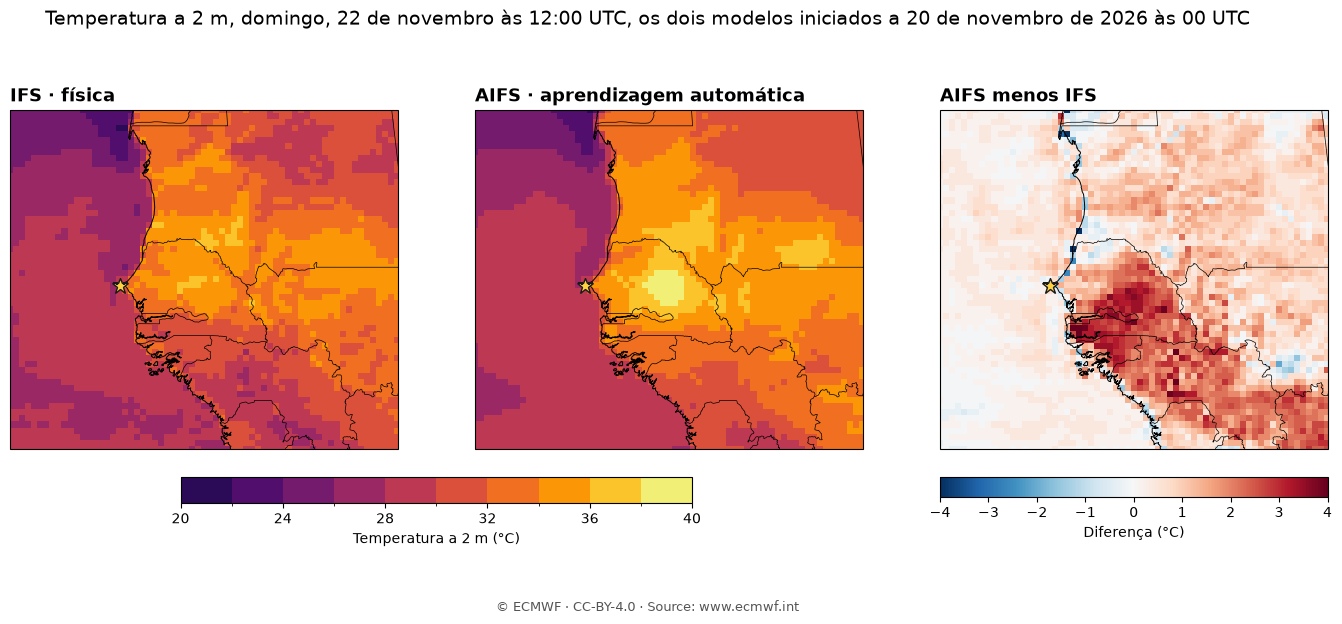

In [5]:
from matplotlib.colors import BoundaryNorm, ListedColormap
levels = [20, 22, 24, 26, 28, 30, 32, 34, 36, 38, 40]
cmap = ListedColormap(plt.get_cmap("inferno")(np.linspace(0.15, 0.95, len(levels) - 1)))
fig, axs = plt.subplots(1, 3, figsize=(17, 6.2), subplot_kw=dict(projection=ccrs.PlateCarree()))
for ax, da, title in ((axs[0], ifs, "IFS · física"), (axs[1], aifs, "AIFS · aprendizagem automática")):
    m = ax.pcolormesh(da.longitude, da.latitude, da, cmap=cmap, norm=BoundaryNorm(levels, cmap.N))
    ax.set_title(title, fontsize=13, fontweight="bold", loc="left")
fig.colorbar(m, ax=axs[:2], orientation="horizontal", shrink=0.6, pad=0.06, label="Temperatura a 2 m (°C)")
d = axs[2].pcolormesh(diff.longitude, diff.latitude, diff, cmap="RdBu_r", vmin=-4, vmax=4)
axs[2].set_title("AIFS menos IFS", fontsize=13, fontweight="bold", loc="left")
fig.colorbar(d, ax=axs[2], orientation="horizontal", pad=0.06, label="Diferença (°C)")
for ax in axs:
    ax.set_extent([AREA[1], AREA[3], AREA[2], AREA[0]]); ax.coastlines(lw=0.7); ax.add_feature(__import__("cartopy").feature.BORDERS, lw=0.5)
    ax.plot(-17.467, 14.716, "*", ms=12, color="#ffd23f", mec="#1a1a1a", transform=ccrs.PlateCarree())
fig.suptitle(f"Temperatura a 2 m, {dia(valid)} às {valid:%H}:00 UTC, os dois modelos iniciados a {data_pt(run)} às {run:%H} UTC", fontsize=14)
fig.text(0.5, 0.01, "© ECMWF · CC-BY-4.0 · Source: www.ecmwf.int", ha="center", fontsize=9, color="#555")
fig.savefig("aifs_vs_ifs_pt.png", dpi=110, bbox_inches="tight")
plt.show()

## 4 · A sua vez 🌍

- **Mais longe:** `STEP = 144` (seis dias). Os dois modelos costumam afastar-se com o prazo de previsão.
- **Outra variável:** `param="10u"` ou `"msl"` (pressão ao nível médio do mar; divida por 100 para hPa).
- **Os ensembles:** ambos têm também ensembles abertos: `model="aifs-ens"` ou `"ifs"` com `stream="enfo"`.

### Dados e licença
Os dados abertos do ECMWF são gratuitos sob a licença **Creative Commons CC-BY-4.0**:
`© ECMWF · Source: www.ecmwf.int · CC-BY-4.0 and ECMWF Terms of Use`. Sem conta, sem chave.

[Dados abertos do ECMWF](https://www.ecmwf.int/en/forecasts/datasets/open-data) · [earthkit](https://earthkit.ecmwf.int)